Testing a different approch of VM2R

In [1]:
# import the libraries
import h5py
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib import cm, colors as mcolors
import matplotlib.ticker as mticker
from pybaselines import Baseline, utils 
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting



# import imageio # to collect frames and write them into an animated file.
import os
# from PIL import Image
# import io

import scienceplots
plt.style.use(['science', 'no-latex'])


import matplotlib.gridspec as gridspec
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch



#from concurrent.futures import ProcessPoolExecutor


# Load the data

# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# # Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = True

In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e9
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [4]:
datasets.keys()

dict_keys(['scan/000/P1_ND0', 'scan/000/P1_ND1', 'scan/001/P0_ND0', 'scan/001/P0_ND1', 'scan/001/P1_ND0', 'scan/001/P1_ND1'])

In [5]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793 1.793 ... 3.498 3.498
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [6]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_ghz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values





# Spectrum to dB
spectrum_db = 10*np.log10(spectrum**2)
mean_spectrum_db = np.mean(spectrum_db, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [7]:
spectrum

array([[1.62633487e+12, 1.60779262e+12, 1.62576990e+12, ...,
        3.61920169e+10, 3.50767273e+10, 3.57459900e+10],
       [1.62652619e+12, 1.61924841e+12, 1.60258069e+12, ...,
        3.61068036e+10, 3.52317424e+10, 3.52680635e+10],
       [1.64633895e+12, 1.65222040e+12, 1.64031712e+12, ...,
        3.61650070e+10, 3.64314686e+10, 3.50664922e+10],
       ...,
       [1.57274583e+12, 1.65748844e+12, 1.61378963e+12, ...,
        3.54431025e+10, 3.54236929e+10, 3.56015534e+10],
       [1.64584148e+12, 1.61251733e+12, 1.60301404e+12, ...,
        3.60267200e+10, 3.61457128e+10, 3.46686750e+10],
       [1.59395278e+12, 1.60042794e+12, 1.56611593e+12, ...,
        3.48534605e+10, 3.53158156e+10, 3.58832637e+10]],
      shape=(634, 63877))

In [8]:

# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=16)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=16)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()



            plt.savefig(
            f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.png",
            dpi=300,
            bbox_inches="tight"
        )

            plt.savefig(
                f"/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/outliers_{i+1}_at_{freq[peak_index]:.4f}.pdf",
                dpi=300,
                bbox_inches="tight"
            )



    return results_outliers


# RFI mask

def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask


# Compute VM^2R for single-dish data
def variance_to_median_square_ratio_single_dish(
    obj,
    time_dim: str = "time",
    freq_dim: str = "freq",
    pol_dim: str | None = None,
    eps: float = 1e-12,
) -> xr.Dataset:
    """
    Compute the variance-to-median-square ratio (VM^2R) over time for a
    single-dish dataset.

    Parameters
    ----------
    obj : xr.DataArray or xr.Dataset
        Input dynamic spectrum. If a Dataset is provided, the first data variable
        is used. Expected dimensions include time and frequency, and optionally
        polarization.
    time_dim : str, optional
        Name of the time dimension. Default is "time".
    freq_dim : str, optional
        Name of the frequency dimension. Default is "freq".
    pol_dim : str or None, optional
        Name of the polarization/feed dimension, if present. If None, the
        function assumes no extra per-feed/pol dimension. Default is None.
    eps : float, optional
        Small positive floor used to avoid division by zero. Default is 1e-12.

    Returns
    -------
    xr.Dataset
        Contains:
        - median: time-median per (freq[, pol])
        - variance: time-variance per (freq[, pol])
        - vm2r: variance / median^2 per (freq[, pol])
        - vm2r_by_freq: median VM^2R over polarization/feed (if pol_dim exists),
                        otherwise same as vm2r
        - vm2r_by_pol: median VM^2R over frequency (if pol_dim exists)
        - vm2r_global: global median VM^2R

    Notes
    -----
    VM^2R = Var(X) / Median(X)^2

    For single-dish total-power data this is useful for flagging non-stationary,
    bursty, or RFI-like behaviour in the time-frequency plane.
    """
    # Handle Dataset vs DataArray
    if isinstance(obj, xr.Dataset):
        var_name = list(obj.data_vars)[0]
        data_da = obj[var_name]
    else:
        data_da = obj

    # Check required dims
    required_dims = {time_dim, freq_dim}
    missing = required_dims - set(data_da.dims)
    if missing:
        raise ValueError(f"Input is missing required dimensions: {missing}")

    if pol_dim is not None and pol_dim not in data_da.dims:
        raise ValueError(f"pol_dim='{pol_dim}' not found in input dimensions {data_da.dims}")

    # Compute time statistics
    x = data_da.chunk({time_dim: -1})
    time_median = x.median(dim=time_dim, skipna=True).rename("median")
    time_variance = x.var(dim=time_dim, skipna=True).rename("variance")

    # VM^2R
    denom = time_median**2
    vm2r = (time_variance / denom).rename("vm2r")
    vm2r = vm2r.where(np.abs(time_median) > eps)

    out = {
        "median": time_median,
        "variance": time_variance,
        "vm2r": vm2r,
    }

    # 1D summaries
    if pol_dim is not None:
        vm2r_by_pol = (
            vm2r.chunk({freq_dim: -1})
            .median(dim=freq_dim, skipna=True)
            .rename("vm2r_by_pol")
        )
        vm2r_by_freq = (
            vm2r.chunk({pol_dim: -1})
            .median(dim=pol_dim, skipna=True)
            .rename("vm2r_by_freq")
        )
        out["vm2r_by_pol"] = vm2r_by_pol
        out["vm2r_by_freq"] = vm2r_by_freq
    else:
        out["vm2r_by_freq"] = vm2r.rename("vm2r_by_freq")

    # Global median
    vm2r_global = xr.DataArray(
        np.nanmedian(vm2r.compute().values),
        name="vm2r_global"
    )
    out["vm2r_global"] = vm2r_global

    return xr.Dataset(out)

In [9]:

n_time, n_freq = spectrum.shape

# --- Configuration ---
n_samples = 20
idx = np.linspace(0, n_time - 1, n_samples, dtype=int)

# --- Convert Time to UTC Datetime ---
time_utc = pd.to_datetime(time, unit="s", utc=True)

# --- Convert time to numeric seconds (for 3D axis) ---
time_seconds = np.array(
    [(t - time_utc[0]).total_seconds() for t in time_utc]
)

# --- Compute detrended power + corrected spectra ---
det_power = np.zeros(n_time)
corrected_spectra = []
selected_times = []
# 1. Calculate scalar power for each selected index
det_power_list = []
for k in idx:
    spectra = spectrum_db[k, :]
    corrected = base_correction(frequency, spectra)
    corrected_spectra.append(corrected)
    
    # Calculate scalar power in dB
    # pwr = 10 * np.log10(np.nanmean(corrected**2))
    det_power_list.append(corrected_spectra)
    selected_times.append(time_seconds[k])

det_power_array = np.array(det_power_list)

In [10]:
corrected_spectra_array = np.array(corrected_spectra)
corrected_spectra_array.shape

(20, 63877)

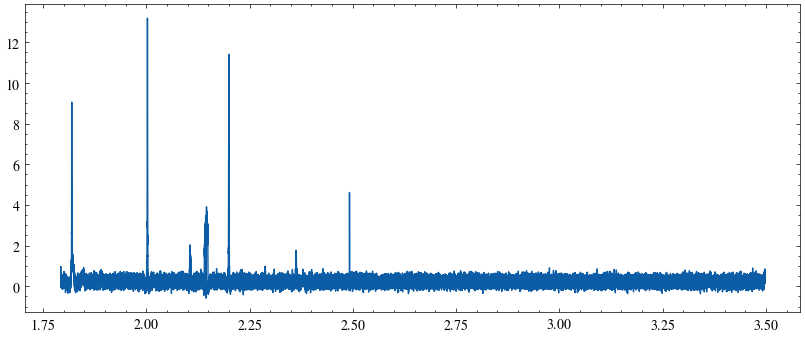

In [11]:
plt.figure(figsize=(10, 4))
plt.plot(frequency, corrected_spectra_array[0,:])

In [12]:
frequency[0]

np.float64(1.7927112579345703)

In [13]:
vm2r_list_high = [] # list to store the VM^2R values for high level RFI
vm2r_list_low = [] # list to store the VM^2R values for high level RFI


window = 50
high_peak_freqiency = []
for k in idx:

    # Avoid overflow at the end
    if k + window > n_time:
        continue

    spectra_block = spectrum[k:k+window, :]
    spectra_block_mean = np.mean(spectra_block, axis=0)
    spectra_block_correction = base_correction(frequency, spectra_block_mean)




    da_high = xr.DataArray(
        spectra_block,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': frequency
        }
    )

    vm2r_results_high = variance_to_median_square_ratio_single_dish(
        da_high,
        time_dim='time',
        freq_dim='frequency'
    )
    vm2r_freq = vm2r_results_high['vm2r_by_freq'].values
    vm2r_list_high.append(vm2r_freq)
    

    #-----------------------------------------------------------------#
    #                                                                 #
    #         Flag the high level RFI                                 #
    #                                                                 #
    #                                                                 #
    #-----------------------------------------------------------------#     


    # Find peaks above 1 sigma from the MAD
    sigma_value = 3
    peak, propreties = find_peaks(spectra_block_correction, 
                                height=MAD(spectra_block_correction) + sigma_value*np.std(spectra_block_correction),
                                distance=10,
                                prominence=1
                                )
    
    peak_freqs = [f"{f:.4f}" for f in frequency[peak]]
    print(f'Peak frequencies to analyze: {peak_freqs}')
    peak_freqs = [float(f) for f in peak_freqs]
    high_peak = quantify_all_outliers(frequency, spectra_block_correction, peak_freqs, plot=False)
    
    mask_high = build_rfi_mask(frequency, high_peak)

    # mask_signal = spectra_block[:,~mask_high]
    # mask_frequency = frequency[~mask_high]

    mask_signal = spectra_block.copy()

    # Replace RFI channels with NaN
    mask_signal[:, mask_high] = np.nan

    # plt.figure(figsize=(10, 6))
    # plt.plot(mask_frequency, mask_signal.mean(axis=0))
    # plt.plot(frequency_ghz[peak_freqs], spectra_block_correction[peak_freqs], 'x', color='red', label='Detected Peaks $>3σ$')


    #break


    mask_frequency = frequency

    # # print(f'spectra block shape: {spectra_block.shape}')
    # #print(f'Frequency at high peaks: {frequency[peak_freqs]} GHz')


    da_low = xr.DataArray(
        mask_signal,
        dims=['time', 'frequency'],
        coords={
            'time': np.arange(window),
            'frequency': mask_frequency
        }
    )

    vm2r_results_low = variance_to_median_square_ratio_single_dish(
        da_low,
        time_dim='time',
        freq_dim='frequency'
    )

    vm2r_freq = vm2r_results_low['vm2r_by_freq'].values

    vm2r_list_low.append(vm2r_freq)

    #break

#convert list to array
vm2r_array_high = np.array(vm2r_list_high)
vm2r_array_low = np.array(vm2r_list_low)

Peak frequencies to analyze: ['1.8196', '2.0028', '2.1408', '2.1413', '2.1416', '2.1419', '2.1424', '2.1428', '2.1431', '2.1434', '2.1439', '2.1442', '2.1459', '2.1464', '2.1469', '2.1473', '2.1476', '2.1479', '2.1484', '2.1487', '2.1999', '2.4920']

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 3187863876470.0869 dB
  Start Frequency: 1.8167 GHz
  End Frequency  : 1.8266 GHz
  Bandwidth      : 0.0099 GHz
  Corrupted Ch.  : 370 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 6752613420512.4648 dB
  Start Frequency: 2.0004 GHz
  End Frequency  : 2.0049 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 169 channels

Outlier 3:
  Peak Frequency : 2.1408 GHz
  Peak Power     : 584785360261.4541 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.1446 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 4:
  Peak Frequency : 2.1413 GHz
  Peak Power     : 558820671186.0859 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.144

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8196', '2.0028', '2.1407', '2.1411', '2.1416', '2.1419', '2.1424', '2.1429', '2.1434', '2.1440', '2.1459', '2.1841', '2.1999', '2.4920']

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 3188515743318.5635 dB
  Start Frequency: 1.8164 GHz
  End Frequency  : 1.8268 GHz
  Bandwidth      : 0.0104 GHz
  Corrupted Ch.  : 391 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 6755943774317.5010 dB
  Start Frequency: 2.0004 GHz
  End Frequency  : 2.0049 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 168 channels

Outlier 3:
  Peak Frequency : 2.1407 GHz
  Peak Power     : 496265565603.7729 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.1446 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 4:
  Peak Frequency : 2.1411 GHz
  Peak Power     : 499807921974.9436 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.1446 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 5:


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8196', '2.0028', '2.1410', '2.1414', '2.1419', '2.1839', '2.1845', '2.1999', '2.4920']

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 3206677471667.1587 dB
  Start Frequency: 1.8165 GHz
  End Frequency  : 1.8268 GHz
  Bandwidth      : 0.0103 GHz
  Corrupted Ch.  : 384 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 6741000277491.3223 dB
  Start Frequency: 2.0004 GHz
  End Frequency  : 2.0049 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 168 channels

Outlier 3:
  Peak Frequency : 2.1410 GHz
  Peak Power     : 481697725048.5283 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.1446 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 4:
  Peak Frequency : 2.1414 GHz
  Peak Power     : 511309340790.1609 dB
  Start Frequency: 2.1401 GHz
  End Frequency  : 2.1446 GHz
  Bandwidth      : 0.0044 GHz
  Corrupted Ch.  : 166 channels

Outlier 5:
  Peak Frequency : 2.1419 GHz
  Peak Power     : 4

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


... (26 outputs left out)

Peak frequencies to analyze: ['1.8196', '2.0028', '2.1999', '2.4920']

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 3182548142848.1553 dB
  Start Frequency: 1.8166 GHz
  End Frequency  : 1.8267 GHz
  Bandwidth      : 0.0101 GHz
  Corrupted Ch.  : 378 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 6768194924928.2158 dB
  Start Frequency: 2.0004 GHz
  End Frequency  : 2.0049 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 169 channels

Outlier 3:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 6076898190706.6914 dB
  Start Frequency: 2.1975 GHz
  End Frequency  : 2.2022 GHz
  Bandwidth      : 0.0047 GHz
  Corrupted Ch.  : 177 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 1099127911578.5542 dB
  Start Frequency: 2.4910 GHz
  End Frequency  : 2.4931 GHz
  Bandwidth      : 0.0021 GHz
  Corrupted Ch.  : 80 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


Peak frequencies to analyze: ['1.8196', '2.0028', '2.1999', '2.4920']

Outlier 1:
  Peak Frequency : 1.8196 GHz
  Peak Power     : 3174586845170.9600 dB
  Start Frequency: 1.8164 GHz
  End Frequency  : 1.8265 GHz
  Bandwidth      : 0.0100 GHz
  Corrupted Ch.  : 376 channels

Outlier 2:
  Peak Frequency : 2.0028 GHz
  Peak Power     : 6791955507737.0742 dB
  Start Frequency: 2.0004 GHz
  End Frequency  : 2.0049 GHz
  Bandwidth      : 0.0045 GHz
  Corrupted Ch.  : 170 channels

Outlier 3:
  Peak Frequency : 2.1999 GHz
  Peak Power     : 6055974294491.6357 dB
  Start Frequency: 2.1975 GHz
  End Frequency  : 2.2023 GHz
  Bandwidth      : 0.0048 GHz
  Corrupted Ch.  : 179 channels

Outlier 4:
  Peak Frequency : 2.4920 GHz
  Peak Power     : 868425632990.2510 dB
  Start Frequency: 2.4911 GHz
  End Frequency  : 2.4929 GHz
  Bandwidth      : 0.0018 GHz
  Corrupted Ch.  : 66 channels


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/array/numpy_compat.py:57: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/dask/utils.py:78: RuntimeWarning: All-NaN slice encountered
  return func(*args, **kwargs)


In [14]:
vm2r_array_low.shape, vm2r_array_high.shape

((18, 63877), (18, 63877))

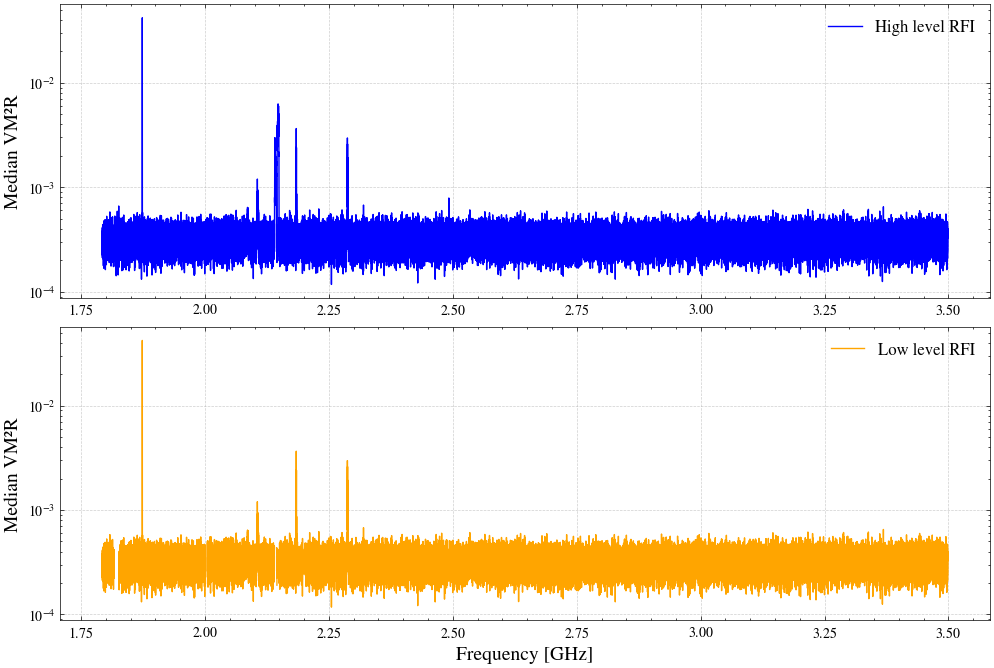

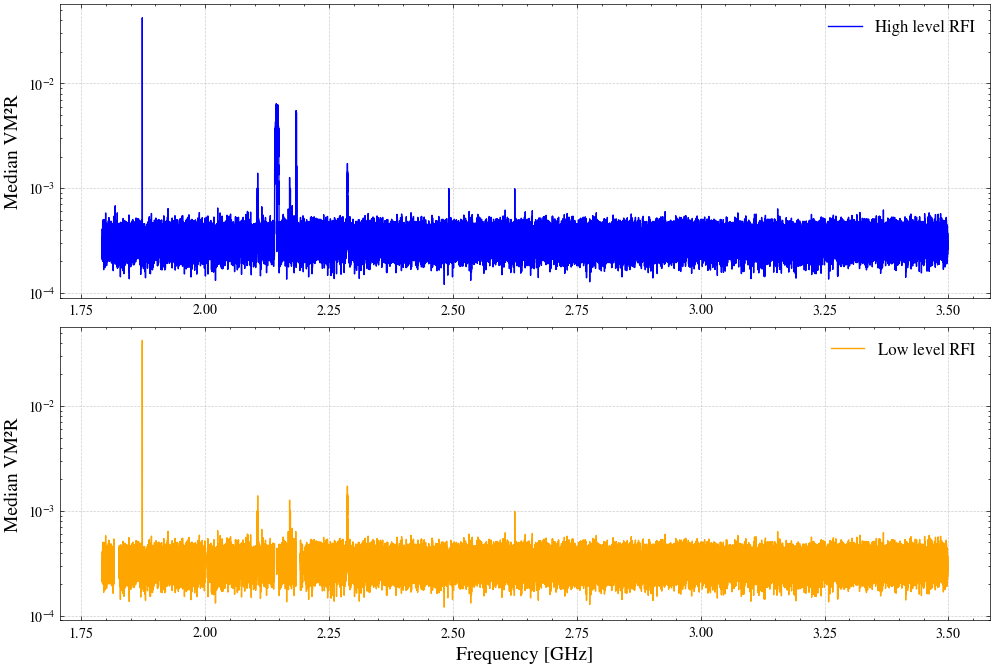

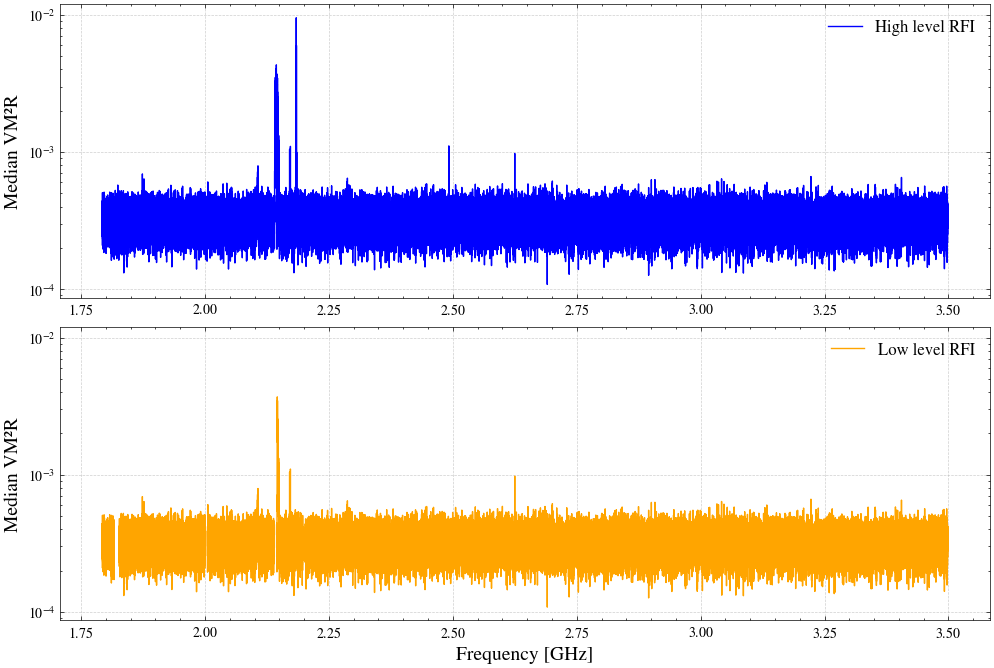

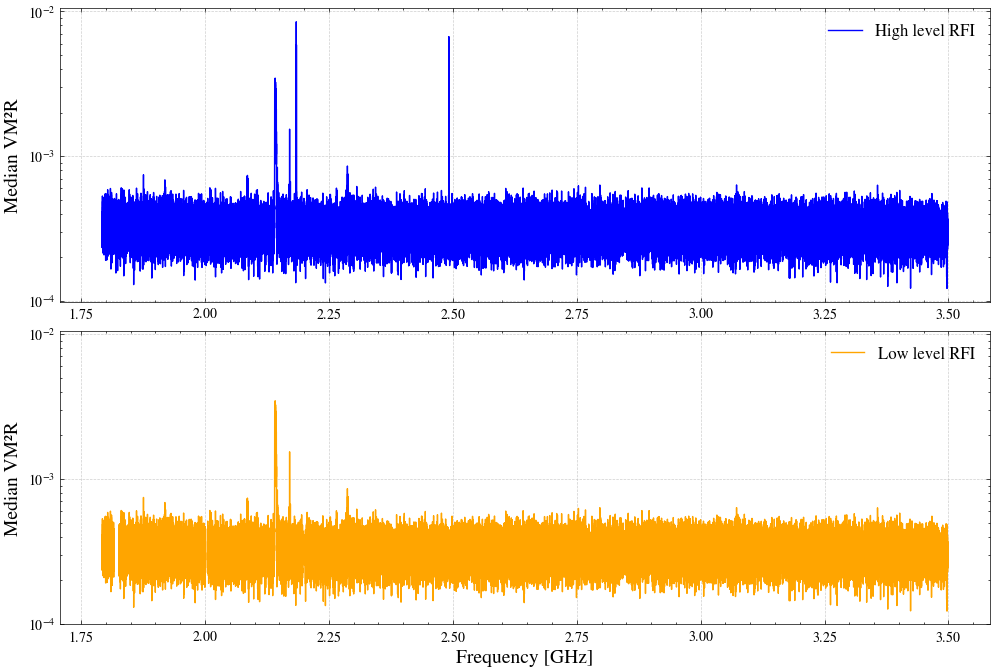

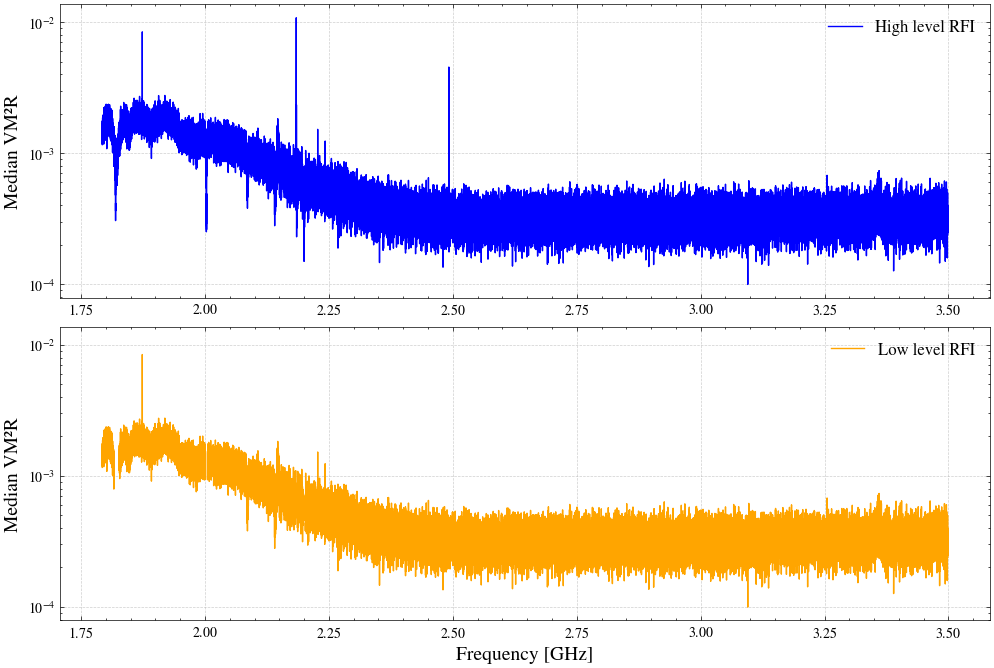

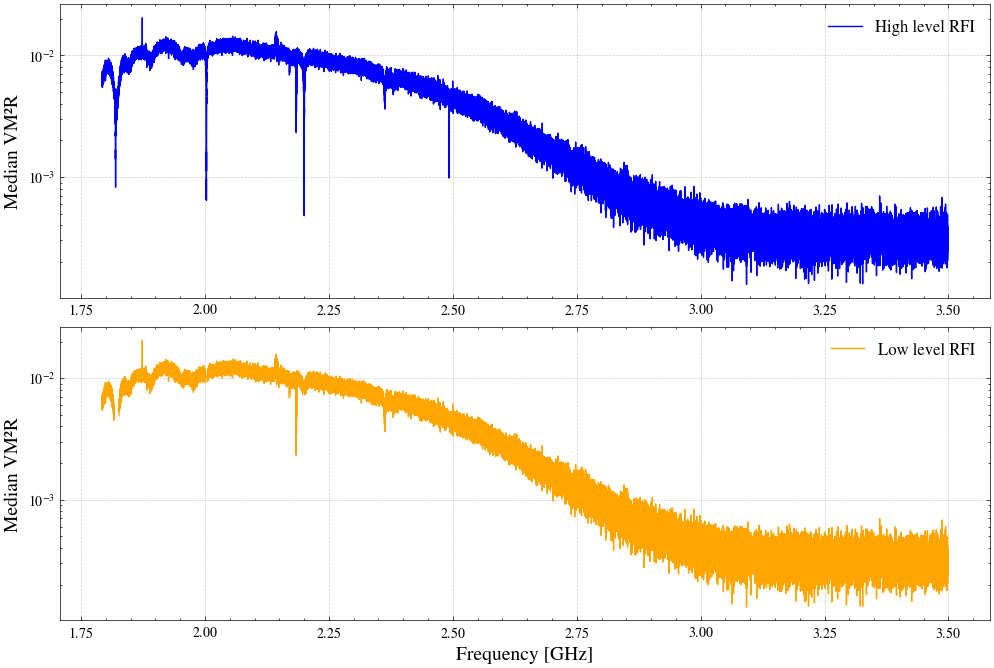

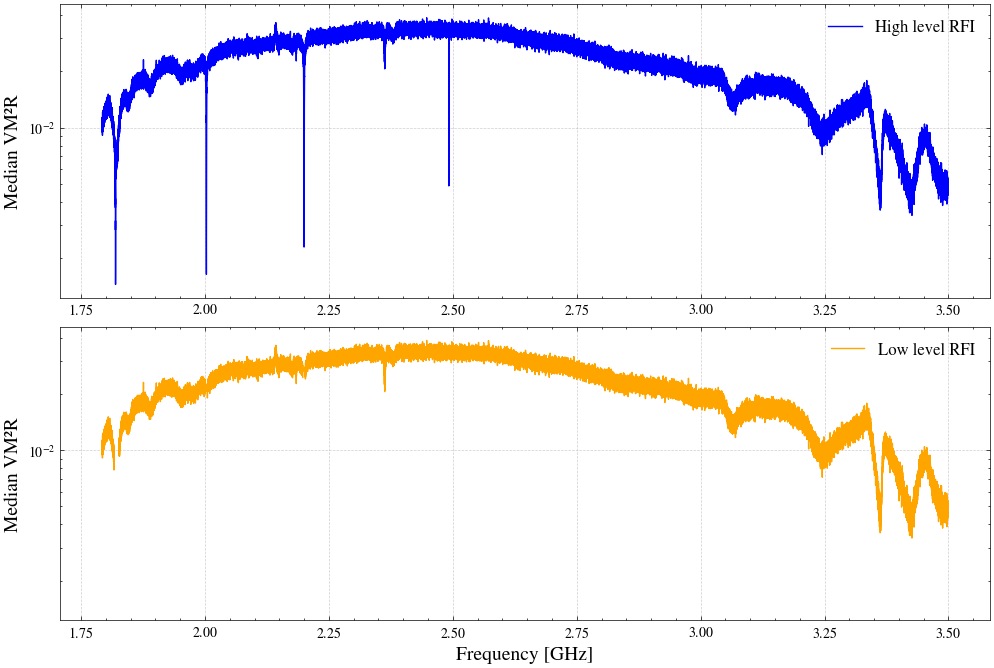

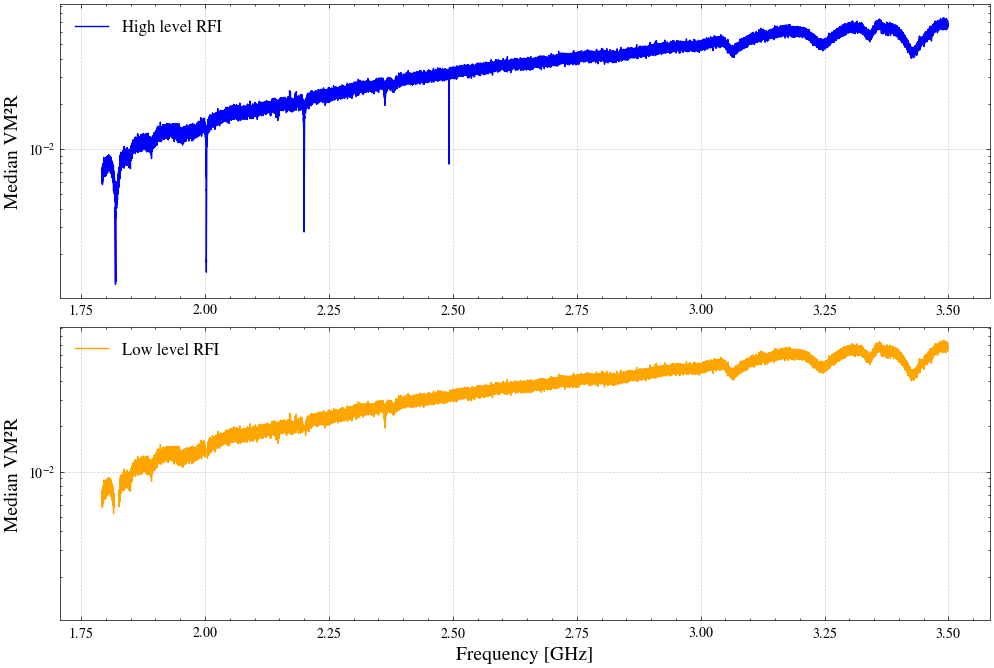

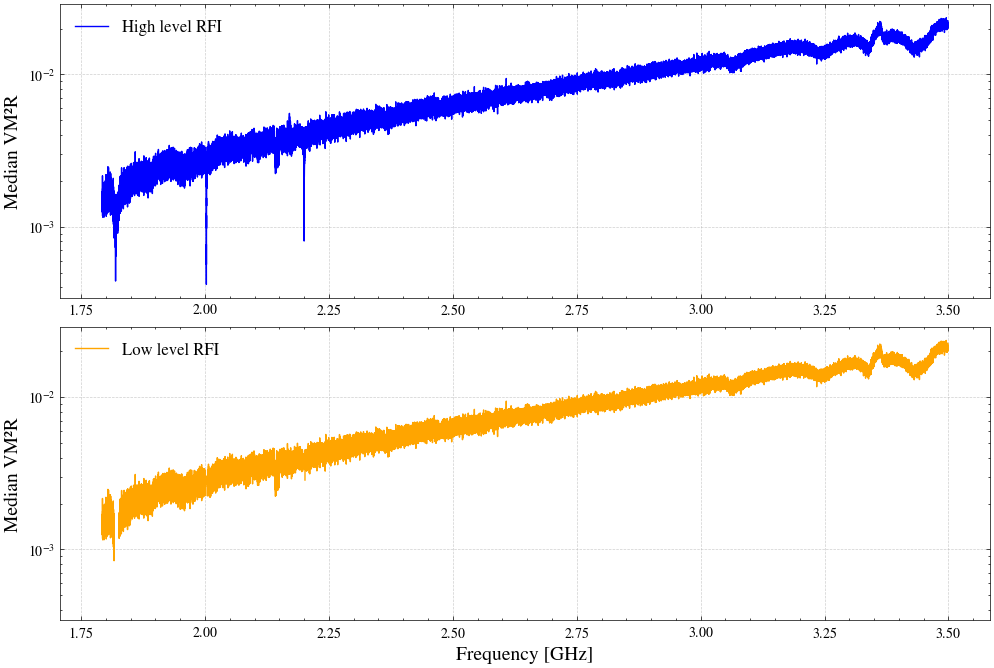

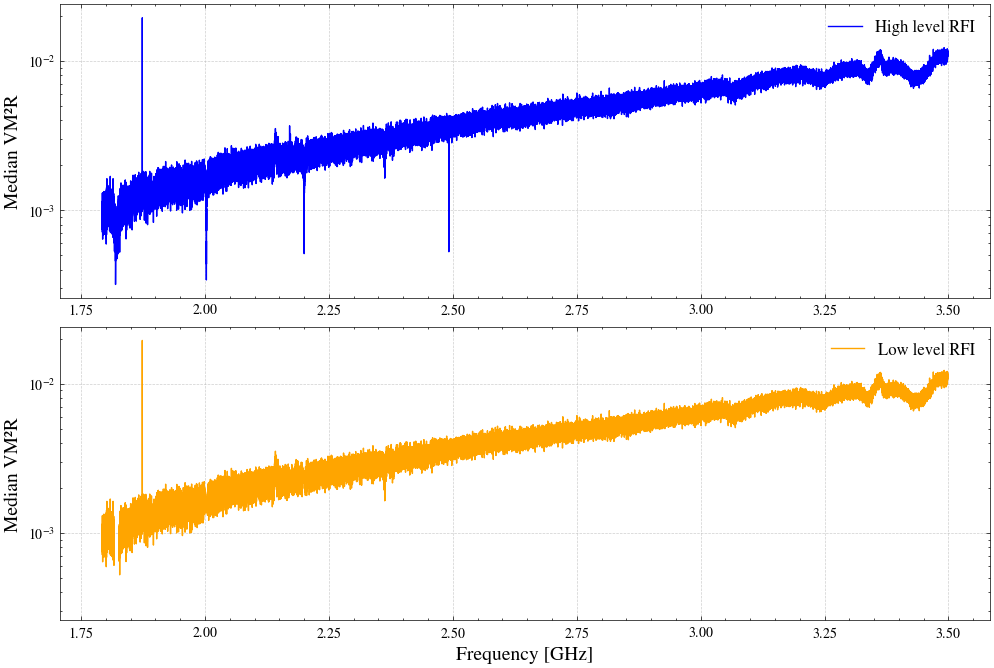

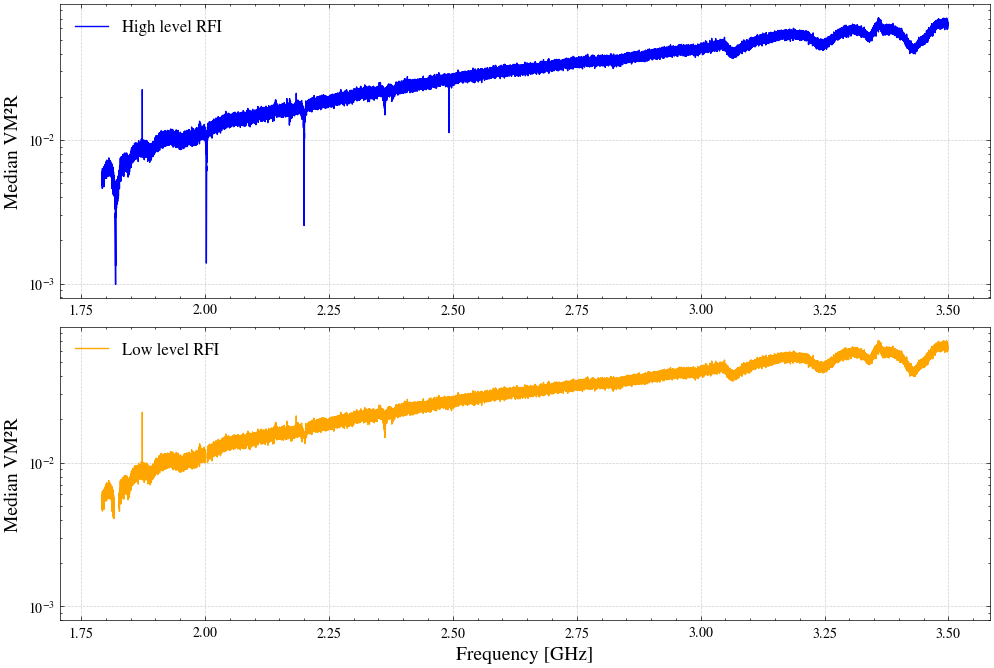

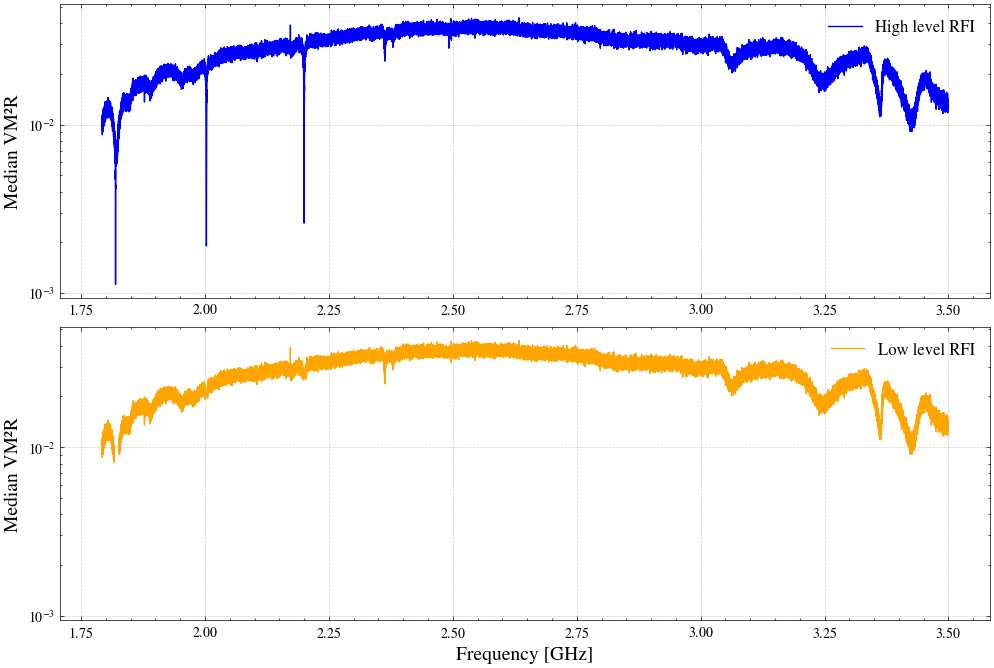

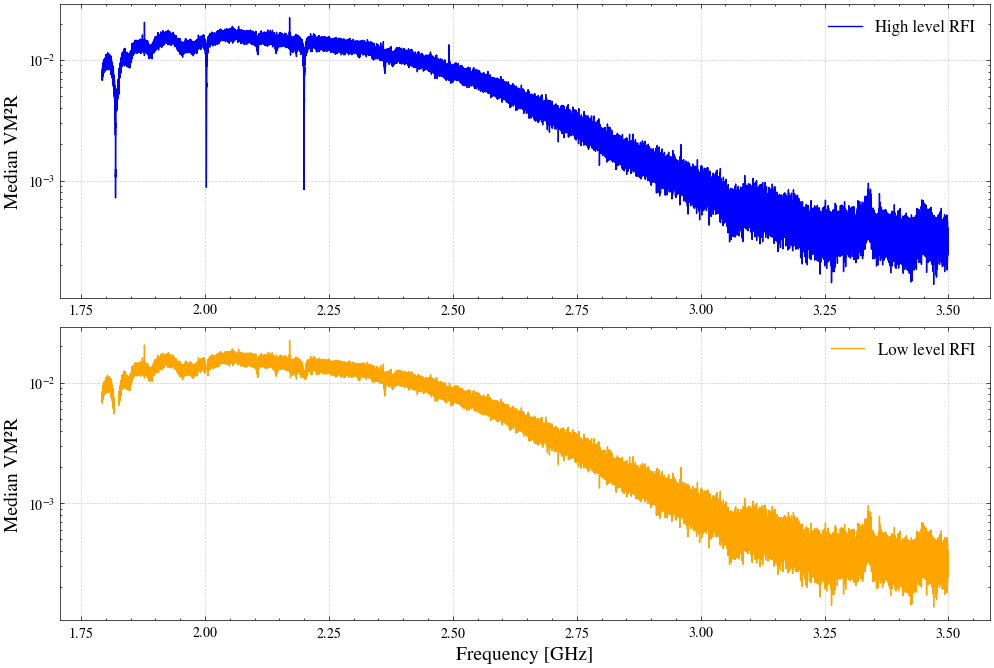

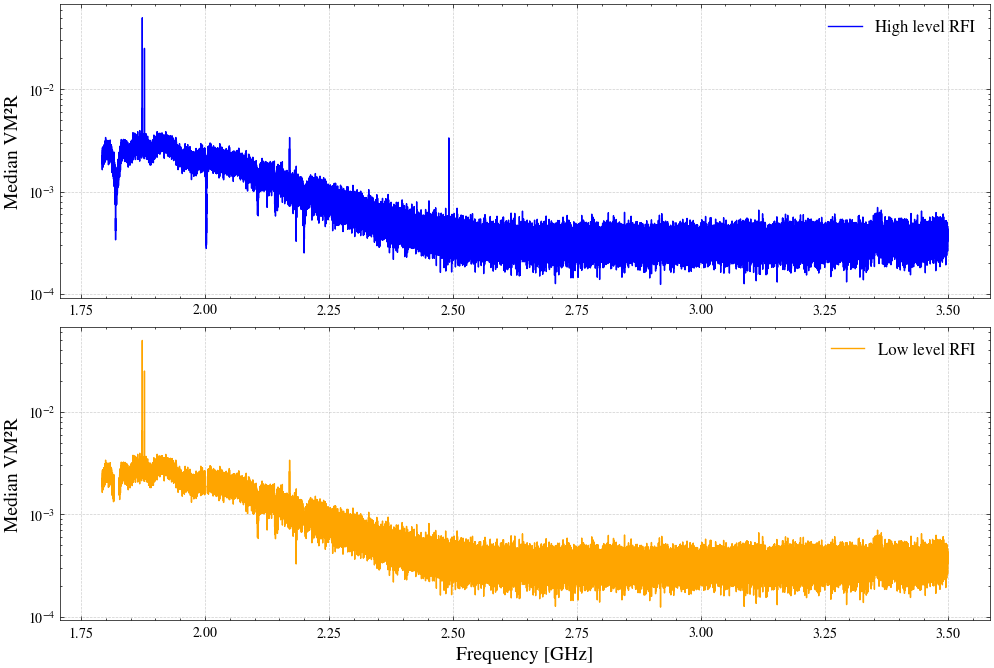

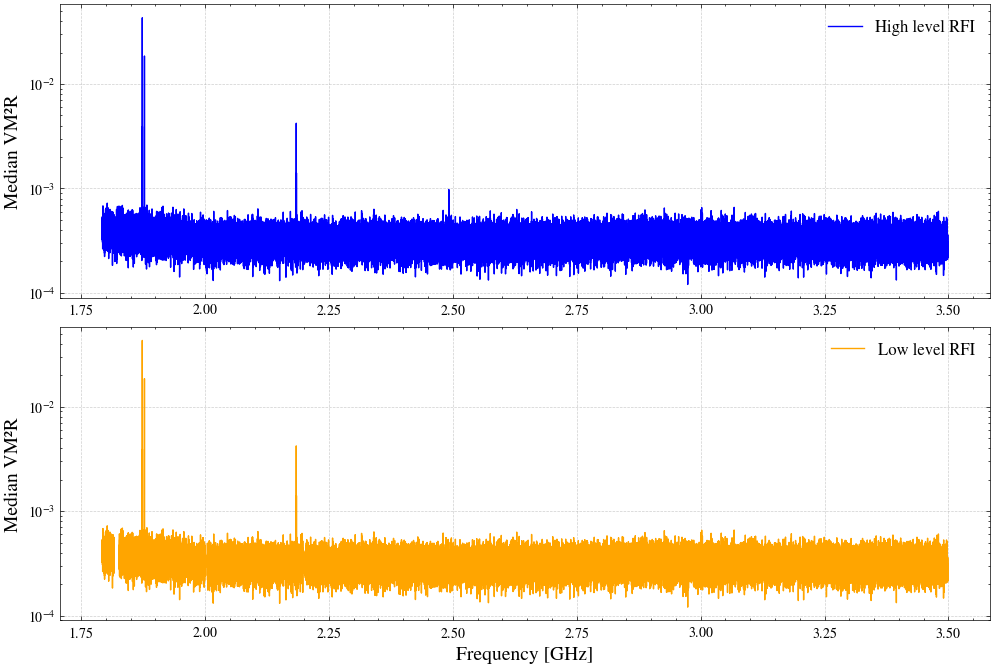

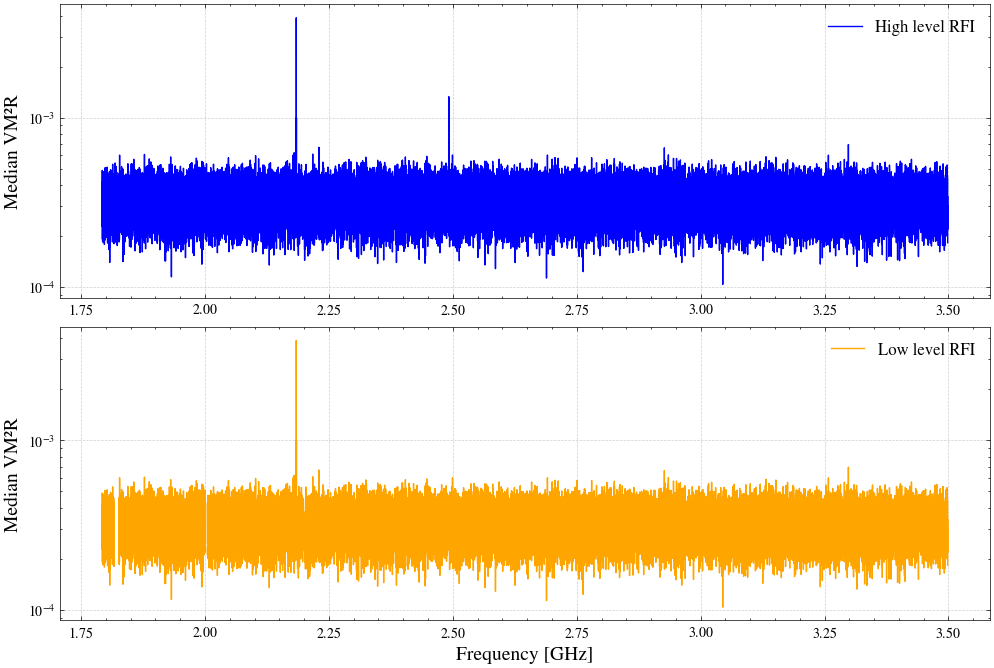

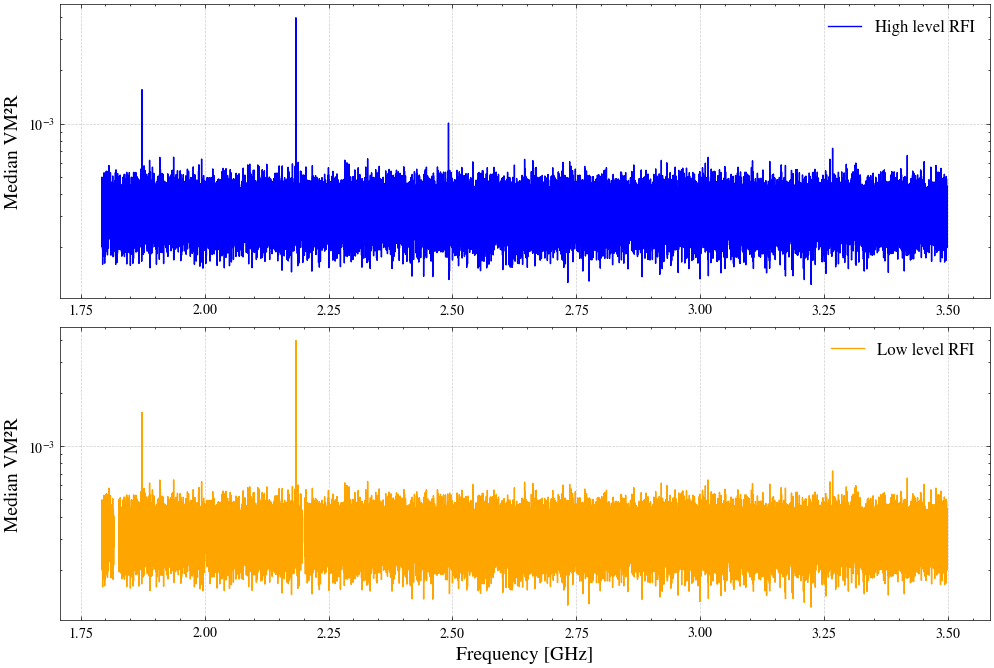

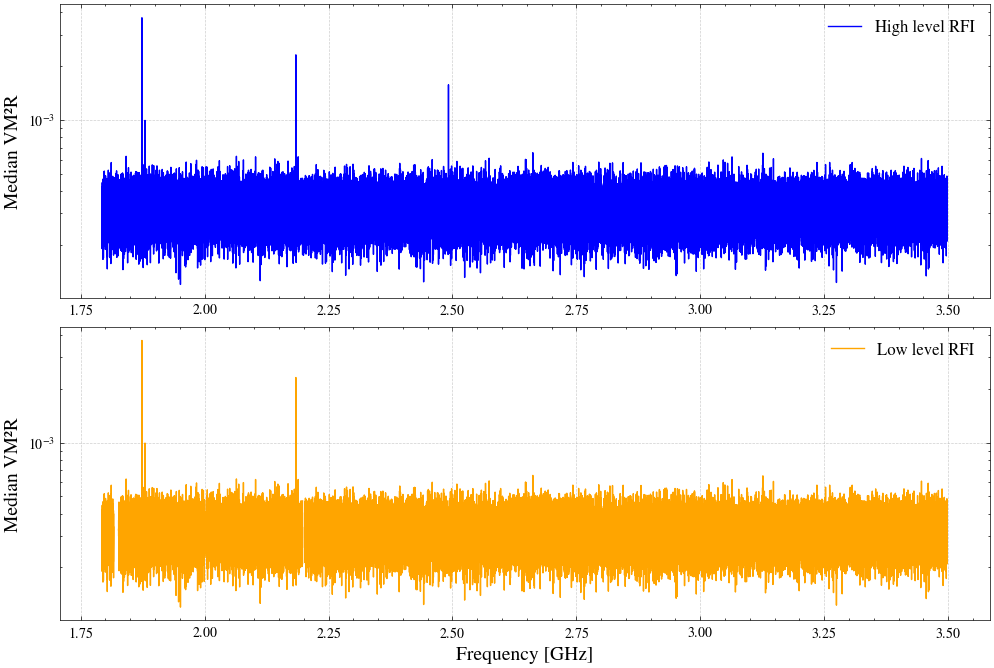

In [15]:

for i in range(vm2r_array_high.shape[0]):
    
    figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
    figure.subplots_adjust(hspace=0.1)
    ax[0].plot(mask_frequency, vm2r_array_high[i,:], color='b', label='High level RFI')  
    ax[0].set_ylabel("Median VM²R", fontsize=14)
    ax[0].grid(True, linestyle='--', alpha=0.6)
    ax[0].legend(fontsize=12)
    ax[0].semilogy()

    ax[1].plot(mask_frequency, vm2r_array_low[i,:], color='orange', label='Low level RFI')
    ax[1].set_xlabel("Frequency [GHz]", fontsize=14)
    ax[1].set_ylabel("Median VM²R", fontsize=14)
    ax[1].grid(True, linestyle='--', alpha=0.6)
    ax[1].legend(fontsize=12)
    ax[1].semilogy()
    
    #break

In [16]:
# Perform median over time for each frequency channel
vm2r_median_high = np.nanmedian(vm2r_array_high, axis=0)
vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)

# Perform median over time for each frequency channel without taking in consideration the NAN
vm2r_median_low_nan = np.median(vm2r_array_low, axis=0)

/tmp/ipykernel_921181/547601547.py:3: RuntimeWarning: All-NaN slice encountered
  vm2r_median_low = np.nanmedian(vm2r_array_low, axis=0)


[]

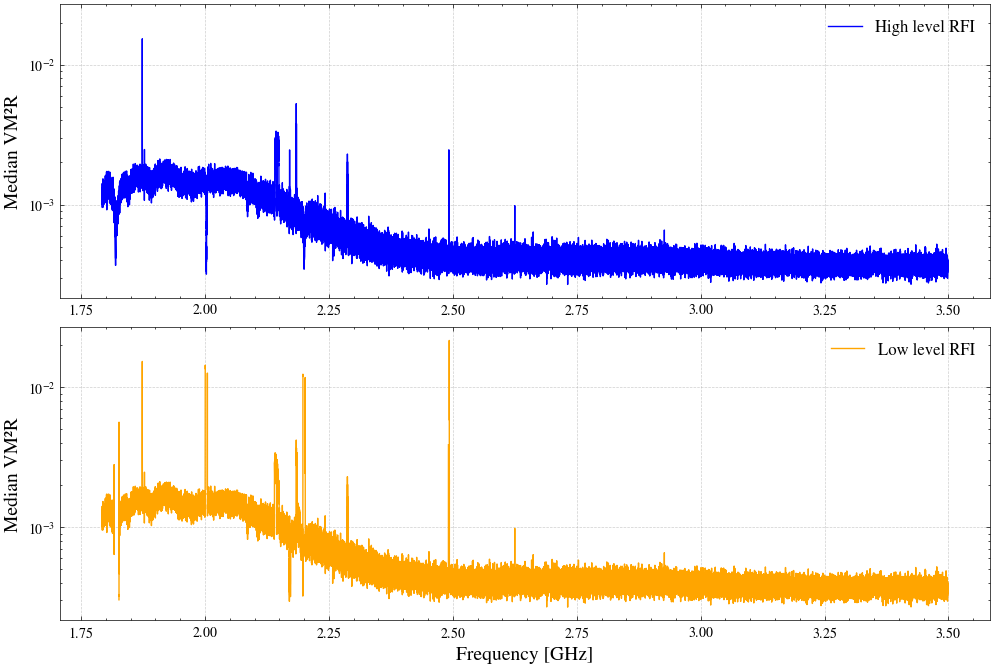

In [17]:
figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
figure.subplots_adjust(hspace=0.1)
ax[0].plot(mask_frequency, vm2r_median_high, color='b', label='High level RFI')  
ax[0].set_ylabel("Median VM²R", fontsize=14)
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend(fontsize=12)
ax[0].semilogy()

ax[1].plot(mask_frequency, vm2r_median_low, color='orange', label='Low level RFI')
ax[1].set_xlabel("Frequency [GHz]", fontsize=14)
ax[1].set_ylabel("Median VM²R", fontsize=14)
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend(fontsize=12)
ax[1].semilogy()





In [18]:
(vm2r_array_high.min()), (vm2r_array_high.max())

(np.float64(9.950360983723088e-05), np.float64(0.07477544945845029))

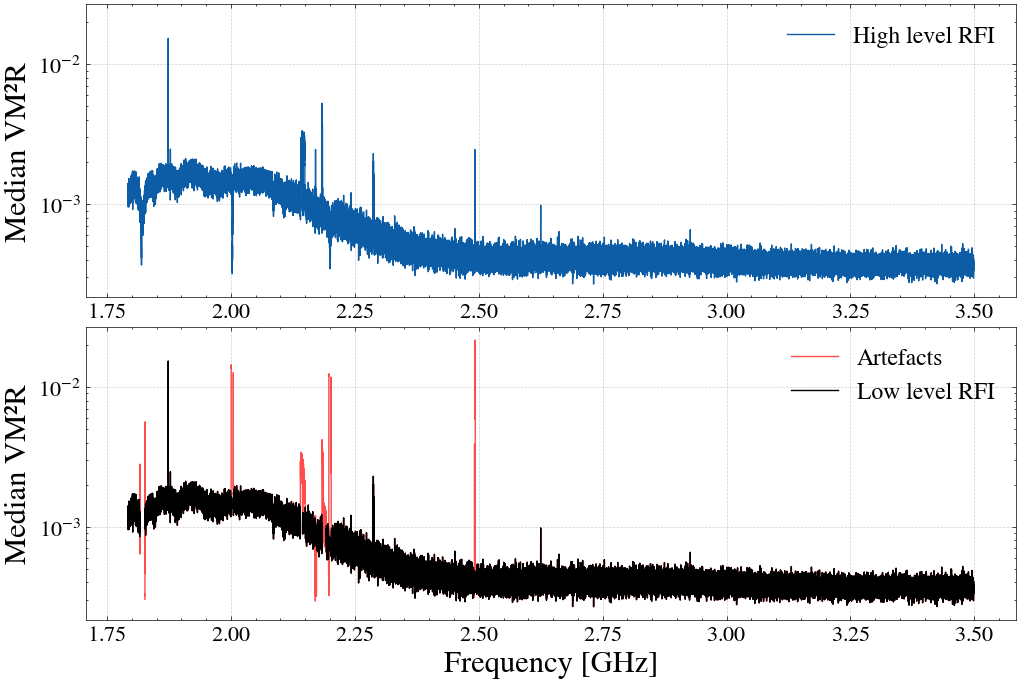

In [27]:
figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
figure.subplots_adjust(hspace=0.1)
#figure.suptitle(f"Median VM²R for high and low level RFI {scan_name}", fontsize=16)
ax[0].plot(mask_frequency, vm2r_median_high, label='High level RFI')  
ax[0].set_ylabel("Median VM²R", fontsize=22)
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend(fontsize=17)
ax[0].tick_params(axis='x', labelsize=16)
ax[0].tick_params(axis='y', labelsize=16)
ax[0].semilogy()


ax[1].plot(frequency, vm2r_median_low,color='r', alpha=0.7, label='Artefacts')
ax[1].plot(frequency, vm2r_median_low_nan, color='black',label='Low level RFI')
ax[1].set_xlabel("Frequency [GHz]", fontsize=22)
ax[1].set_ylabel("Median VM²R", fontsize=22)
#plt.title("Median VM²R low level RFI", fontsize=18)
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].semilogy()
ax[1].tick_params(axis='x', labelsize=16)
ax[1].tick_params(axis='y', labelsize=16)
ax[1].legend(fontsize=17)


# --- Save figure ---
if to_save:
    full_path = os.path.join(dirname, scan_name)
    os.makedirs(full_path, exist_ok=True)

    plot_png = os.path.join(full_path, f'VM2R_{scan_name}.png')
    plot_pdf = os.path.join(full_path, f'VM2R_{scan_name}.pdf')

    plt.savefig(plot_png, dpi=300, bbox_inches='tight')
    plt.savefig(plot_pdf, bbox_inches='tight')


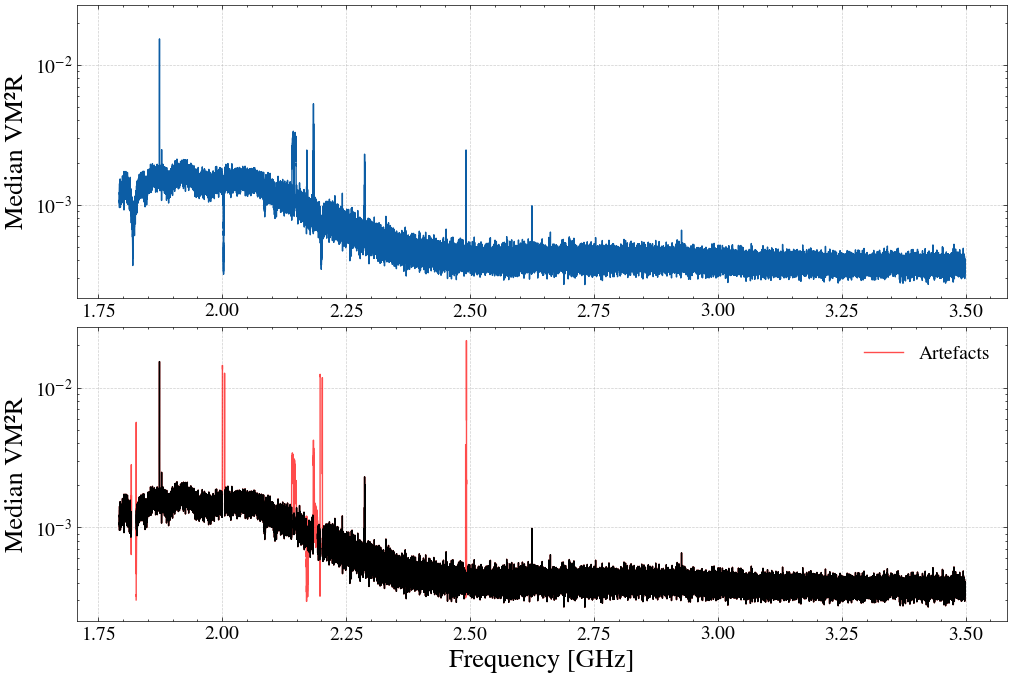

In [ ]:
figure, ax = plt.subplots(2, 1, figsize=(12, 8), sharey=True)
figure.subplots_adjust(hspace=0.1)

# --- Top panel ---
ax[0].plot(mask_frequency, vm2r_median_high)
ax[0].set_ylabel("Median VM²R", fontsize=19)
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].set_yscale('log')
ax[0].tick_params(axis='x', labelsize=14)
ax[0].tick_params(axis='y', labelsize=14)

# --- Bottom panel ---
ax[1].plot(frequency, vm2r_median_low,color='r', alpha=0.7, label='Artefacts')
ax[1].plot(frequency, vm2r_median_low_nan, color='black', alpha=1)
ax[1].set_xlabel("Frequency [GHz]", fontsize=19)
ax[1].set_ylabel("Median VM²R", fontsize=19)
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend(fontsize=14)
ax[1].set_yscale('log')
ax[1].tick_params(axis='x', labelsize=14)
ax[1].tick_params(axis='y', labelsize=14)

# # --- Save figure ---
# if to_save:
#     full_path = os.path.join(dirname, scan_name)
#     os.makedirs(full_path, exist_ok=True)

#     plot_png = os.path.join(full_path, f'VM2R_{scan_name}.png')
#     plot_pdf = os.path.join(full_path, f'VM2R_{scan_name}.pdf')

#     plt.savefig(plot_png, dpi=300, bbox_inches='tight')
#     plt.savefig(plot_pdf, bbox_inches='tight')

plt.show()

[]

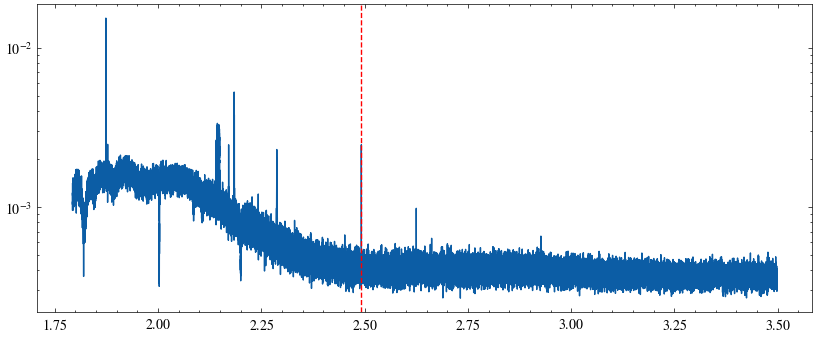

In [21]:
plt.figure(figsize=(10, 4))
plt.plot(frequency, vm2r_median_high)
plt.axvline(2.492 , color='red', linestyle='--')
plt.semilogy()


In [22]:
# Signal to noise ratio

# Step 1: define the baseli fitting
baseline_fitter = Baseline(x_data=frequency)
bkg, params = baseline_fitter.asls(mean_spectrum_db, lam=1e7, p=0.02)

# Step 2: Substract the baseline
correct_baseline = mean_spectrum_db - bkg


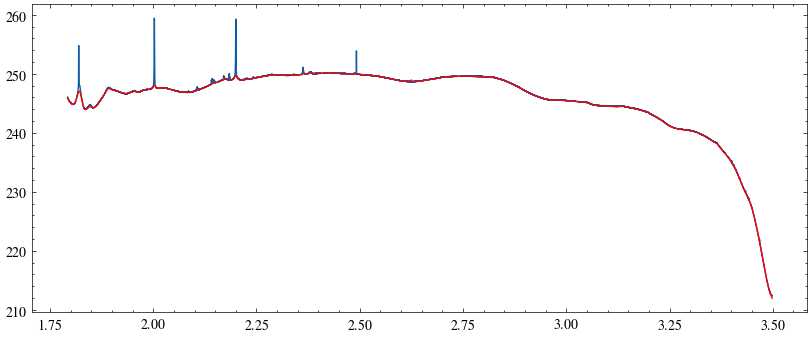

In [23]:
plt.figure(figsize=(10, 4))
plt.plot(frequency, mean_spectrum_db)
plt.plot(frequency, bkg, color='red')

In [24]:
# flux density polynomial fit


def calculate_log_flux(frequency_ghz, coefficients):
    """
    Calculates the log10 of the spectral flux density S using a polynomial expansion.
    
    Parameters:
    - frequency_ghz: float or numpy array of frequencies.
    - coefficients: list or array of polynomial terms [a0, a1, a2, a3, ...]
    """
    # 1. Take the base-10 log of the frequency (log(nu_G))
    log_nu = np.log10(frequency_ghz)
    
    # 2. Initialize the log(S) sum with the intercept term a0
    log_S = coefficients[0]
    
    # 3. Dynamically loop through higher order terms (a1*log_nu, a2*log_nu^2, etc.)
    for order, a_n in enumerate(coefficients[1:], start=1):
        log_S += a_n * (log_nu ** order)
        
    return log_S

In [25]:
TaurusA_coefficients = [2.9516, -0.2173, -0.0473, -0.0674]
log_flux = calculate_log_flux(frequency, TaurusA_coefficients)

log_flux.shape

(63877,)

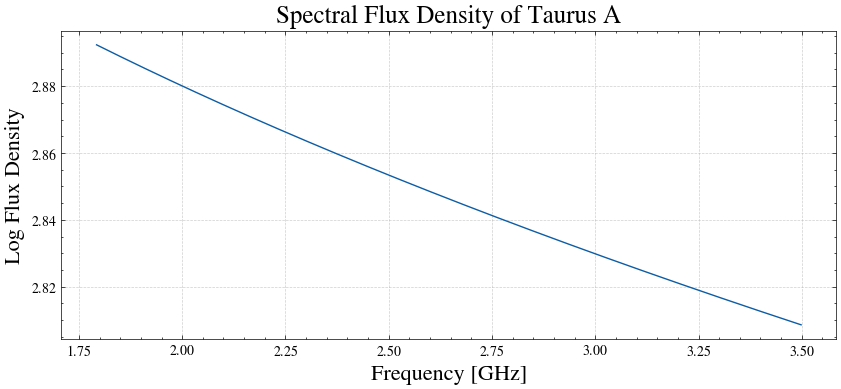

In [26]:
plt.figure(figsize=(10, 4))
plt.plot(frequency, log_flux)
plt.xlabel("Frequency [GHz]", fontsize=16)
plt.ylabel("Log Flux Density", fontsize=16)
plt.title("Spectral Flux Density of Taurus A", fontsize=18)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()